In [1]:
import matplotlib.pyplot as plt
import torch
import segmentation_models_pytorch as smp

from train_unet import PGDataset

%load_ext autoreload
%autoreload 2

2024-04-19 16:43:48.398589: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2024-04-19 16:43:48.427550: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-04-19 16:43:49.013959: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


In [2]:
dataset = PGDataset("../theodore_unet/imgs/", "../theodore_unet/masks/", "../theodore_unet/val.txt")
len(dataset)

5134

In [10]:
# load best saved checkpoint
best_model = torch.load('./runs/baseline_fpn_timm-mobilenetv3_small_100_schedule_25_upd_early_stopping/best.pth')
print(sum(p.numel() for p in best_model.parameters() if p.requires_grad))

DEVICE = "cuda"

ENCODER = 'timm-mobilenetv3_small_100'
ENCODER_WEIGHTS = 'imagenet'

preprocessing_fn = smp.encoders.get_preprocessing_fn(ENCODER, ENCODER_WEIGHTS)

2721953


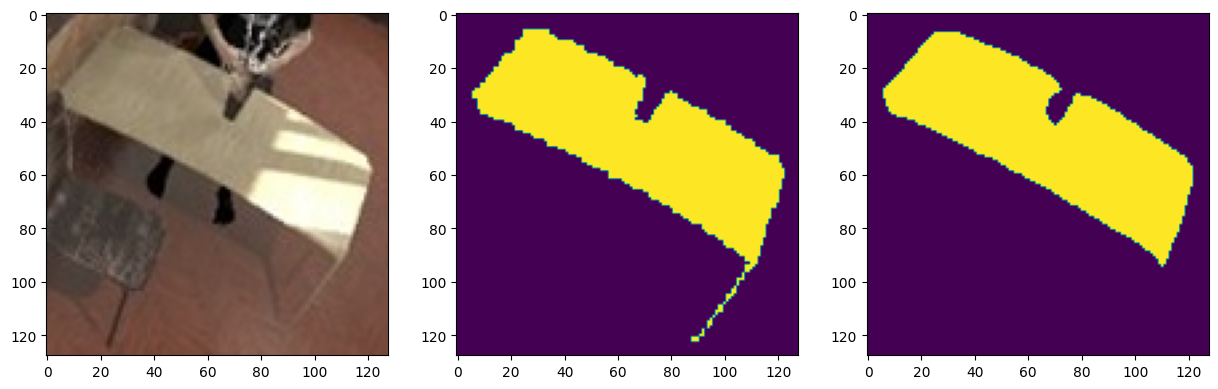

In [14]:
image, gt_mask = dataset[0]

gt_mask = gt_mask.squeeze()

x_tensor = torch.from_numpy(preprocessing_fn(image)).to(DEVICE).permute((2, 0, 1)).unsqueeze(0).float()
pr_mask = best_model.predict(x_tensor)
pr_mask = (pr_mask.squeeze().cpu().numpy().round())

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(image)

plt.subplot(1, 3, 2)
plt.imshow(gt_mask)

plt.subplot(1, 3, 3)
plt.imshow(pr_mask)